<a href="https://colab.research.google.com/github/Rubziguin/Agente-Entrevistador-LLM/blob/main/Simulador_Entrevistas_Agente_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧑‍💻 Simulador de Entrevistas de Código — Mini Agente com IA LLM

**PUC-SP · Ciência da Computação · Inteligência Artificial — Atividade "Agente IA LLM"**
**Grupo D (Engenharia de Chat) · Projeto: _Simulador de Entrevistas de Código_**

**Dupla:** `Rubens Rodrigues Maranesi` · `Pedro Gabriel Takenobu Serafim` &nbsp;&nbsp;

---

### O que este agente faz
Um assistente que atua como **entrevistador técnico de Big Tech**:

1. **Mantém o histórico da conversa** (a API é *stateless*: a memória é a lista de mensagens que reenviamos a cada turno).
2. **Apresenta um desafio de lógica** e conduz o candidato **passo a passo**, dando dicas graduais sem entregar a resposta.
3. **Age através de ferramentas (tool calling):** em vez de "achar" se o código está certo, o LLM chama uma função Python que **executa o código do candidato contra casos de teste reais**.
4. **Avalia de forma construtiva** no fim, com uma **saída estruturada** (JSON validado com Pydantic) e um gráfico das notas.

### Arquitetura (ciclo do agente)
```
 candidato ──► [histórico de mensagens] ──► LLM (OpenAI SDK, Chat Completions)
                       ▲                         │
                       │                ┌────────┴─────────┐
                       │          resposta texto     tool_calls
                       │                │                  │
                       └────────────────┘     ┌────────────▼────────────┐
                                              │ Ferramentas Python       │
                                              │  • sortear_desafio       │
                                              │  • executar_testes       │
                                              └────────────┬────────────┘
                                                           │ resultado (JSON)
                                     volta para o histórico ┘  → LLM decide o próximo passo
```
Percepção (mensagem do candidato + resultado dos testes) → raciocínio (LLM) → ação (ferramentas / resposta) → memória (histórico).

## 1 · Configuração da chave de API (Secrets do Colab)

O notebook usa **a biblioteca `openai`** (OpenAI SDK), que fala o protocolo *Chat Completions* — o mesmo de vários provedores. Basta **uma** destas chaves:

| Provedor | Nome do Secret | Onde obter | Custo |
|---|---|---|---|
| **Google Gemini** (recomendado) | `GEMINI_API_KEY` | https://aistudio.google.com/apikey | camada gratuita |
| OpenAI | `OPENAI_API_KEY` | https://platform.openai.com/api-keys | pré-pago (centavos) |
| Hugging Face | `HF_KEY` | https://huggingface.co/settings/tokens (permissão *Inference Providers*) | créditos gratuitos limitados |

**Como cadastrar no Colab:** clique no ícone de **chave 🔑 (Secrets)** na barra lateral esquerda → **Adicionar novo secret** → em *Nome* coloque, por exemplo, `GEMINI_API_KEY`; em *Valor* cole a chave → ative **Acesso ao notebook**.
Nunca cole a chave direto no código de um notebook que vai para o GitHub.

> **Sem chave?** O notebook roda mesmo assim em **MODO DEMO**: as falas do entrevistador são **simuladas** (roteiro fixo), mas as ferramentas — inclusive a execução real dos testes — funcionam. Assim dá para ver o fluxo completo do agente.

In [15]:
!pip install -q openai pydantic

In [16]:
import os, json, re, sys, time, textwrap, tempfile, subprocess
from types import SimpleNamespace

PROVEDOR   = "auto"   # "auto", "gemini", "openai" ou "huggingface"
PEDIR_CHAVE = False   # True = pede a chave com getpass se não achar nos Secrets

PROVEDORES = {
    "gemini": dict(chaves=["GEMINI_API_KEY", "GOOGLE_API_KEY"],
                   base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
                   modelo="gemini-flash-latest"),
    "openai": dict(chaves=["OPENAI_API_KEY"],
                   base_url="https://api.openai.com/v1",
                   modelo="gpt-5-nano"),
    "huggingface": dict(chaves=["HF_KEY", "HF_TOKEN"],
                        base_url="https://router.huggingface.co/v1",
                        modelo="meta-llama/Llama-3.3-70B-Instruct"),
}

def ler_secret(nome):
    # 1) Secrets do Colab  2) variável de ambiente
    try:
        from google.colab import userdata
        valor = userdata.get(nome)
        if valor:
            return valor
    except Exception:
        pass
    return os.getenv(nome)

def escolher_provedor():
    ordem = list(PROVEDORES) if PROVEDOR == "auto" else [PROVEDOR]
    for nome in ordem:
        for chave in PROVEDORES[nome]["chaves"]:
            valor = ler_secret(chave)
            if valor:
                return nome, valor
    if PEDIR_CHAVE and PROVEDOR != "auto":
        from getpass import getpass
        return PROVEDOR, getpass(f"{PROVEDORES[PROVEDOR]['chaves'][0]}: ")
    return None, None

NOME_PROVEDOR, API_KEY = escolher_provedor()
if NOME_PROVEDOR:
    print(f"Provedor: {NOME_PROVEDOR} · modelo: {PROVEDORES[NOME_PROVEDOR]['modelo']} · chave: {API_KEY[:4]}...{API_KEY[-2:]}")
else:
    print("Nenhuma chave encontrada nos Secrets → o agente vai rodar em MODO DEMO (falas simuladas).")

Provedor: gemini · modelo: gemini-flash-latest · chave: AQ.A...VQ


## 2 · Banco de desafios com casos de teste

Cada desafio tem enunciado, nome da função esperada e **casos de teste**. É isso que permite ao agente **verificar** o código em vez de opinar no escuro.

In [17]:
DESAFIOS = {
    "soma_dois": dict(
        titulo="Two Sum", nivel="facil", funcao="two_sum", comparar="ordenado",
        enunciado=("Escreva `two_sum(nums, alvo)` que recebe uma lista de inteiros e um alvo e devolve "
                   "os **índices** dos dois números cuja soma é igual ao alvo. Existe exatamente uma solução "
                   "e não se pode usar o mesmo elemento duas vezes."),
        testes=[([[2, 7, 11, 15], 9], [0, 1]), ([[3, 2, 4], 6], [1, 2]), ([[3, 3], 6], [0, 1]),
                ([[-1, -2, -3, -4, -5], -8], [2, 4]), ([[0, 4, 3, 0], 0], [0, 3])]),
    "parenteses": dict(
        titulo="Parênteses válidos", nivel="facil", funcao="valido", comparar="exato",
        enunciado=("Escreva `valido(s)` que recebe uma string só com `()[]{}` e devolve `True` se todos os "
                   "símbolos abrem e fecham na ordem correta."),
        testes=[(["()"], True), (["()[]{}"], True), (["(]"], False), (["([)]"], False),
                (["{[]}"], True), ([""], True), (["(("], False)]),
    "palindromo": dict(
        titulo="Palíndromo", nivel="facil", funcao="eh_palindromo", comparar="exato",
        enunciado=("Escreva `eh_palindromo(s)` que devolve `True` se a frase é um palíndromo, ignorando "
                   "maiúsculas/minúsculas, espaços e pontuação."),
        testes=[(["A man, a plan, a canal: Panama"], True), (["race a car"], False), ([" "], True),
                (["Socorram-me, subi no onibus em Marrocos"], True), (["ab"], False)]),
    "sem_repeticao": dict(
        titulo="Maior substring sem repetição", nivel="medio", funcao="maior_substring", comparar="exato",
        enunciado=("Escreva `maior_substring(s)` que devolve o **comprimento** da maior substring sem "
                   "caracteres repetidos."),
        testes=[(["abcabcbb"], 3), (["bbbbb"], 1), (["pwwkew"], 3), ([""], 0), (["dvdf"], 3), (["abba"], 2)]),
    "intervalos": dict(
        titulo="Mesclar intervalos", nivel="medio", funcao="mesclar", comparar="exato",
        enunciado=("Escreva `mesclar(intervalos)` que recebe uma lista de pares `[inicio, fim]` e devolve a "
                   "lista de intervalos sobrepostos já mesclados, ordenada pelo início."),
        testes=[([[[1, 3], [2, 6], [8, 10], [15, 18]]], [[1, 6], [8, 10], [15, 18]]),
                ([[[1, 4], [4, 5]]], [[1, 5]]), ([[[4, 7], [1, 4]]], [[1, 7]]), ([[[1, 2]]], [[1, 2]])]),
}

for k, d in DESAFIOS.items():
    print(f"{k:14} [{d['nivel']:5}] {d['titulo']} — {len(d['testes'])} testes")

soma_dois      [facil] Two Sum — 5 testes
parenteses     [facil] Parênteses válidos — 7 testes
palindromo     [facil] Palíndromo — 5 testes
sem_repeticao  [medio] Maior substring sem repetição — 6 testes
intervalos     [medio] Mesclar intervalos — 4 testes


## 3 · Ferramentas do agente (*tool calling*)

* `sortear_desafio(nivel)` — escolhe um desafio ainda não usado na entrevista.
* `executar_testes(desafio_id)` — pega o **último bloco de código enviado pelo candidato**, roda num **processo Python separado, com tempo limite**, e devolve quais testes passaram.

> O código do candidato roda num subprocesso isolado (`python -I`, diretório temporário, timeout de 5 s). Isso evita travar o notebook, mas **não é um sandbox de segurança completo** — em produção usaríamos um container.

In [18]:
def extrair_codigo(texto):
    # Pega o último bloco ```python ...``` (ou ``` ... ```); se não houver, aceita texto que tenha 'def '.
    blocos = re.findall(r"```(?:python|py)?\s*\n(.*?)```", texto or "", flags=re.S)
    if blocos:
        return blocos[-1]
    return texto if texto and "def " in texto else None

HARNESS = r'''
import json, sys
dados = json.loads(sys.stdin.read())
ns = {}
try:
    exec(dados["codigo"], ns)
except Exception as e:
    print(json.dumps({"erro": f"Erro ao carregar o código: {type(e).__name__}: {e}"})); sys.exit()
f = ns.get(dados["funcao"])
if not callable(f):
    print(json.dumps({"erro": f"Função '{dados['funcao']}' não encontrada no código."})); sys.exit()
def norm(x, modo):
    if modo == "ordenado" and isinstance(x, (list, tuple)):
        return sorted(x)
    return [list(i) for i in x] if isinstance(x, (list, tuple)) and x and isinstance(x[0], tuple) else x
res = []
for args, esperado in dados["testes"]:
    try:
        obtido = f(*args)
        ok = norm(obtido, dados["comparar"]) == norm(esperado, dados["comparar"])
        res.append({"entrada": args, "esperado": esperado, "obtido": repr(obtido)[:200], "passou": ok})
    except Exception as e:
        res.append({"entrada": args, "esperado": esperado, "obtido": f"{type(e).__name__}: {e}", "passou": False})
print(json.dumps({"resultados": res}))
'''

def rodar_testes(desafio_id, codigo, timeout=5):
    d = DESAFIOS[desafio_id]
    entrada = json.dumps(dict(codigo=codigo, funcao=d["funcao"], testes=d["testes"], comparar=d["comparar"]))
    with tempfile.TemporaryDirectory() as tmp:
        try:
            p = subprocess.run([sys.executable, "-I", "-c", HARNESS], input=entrada, capture_output=True,
                               text=True, timeout=timeout, cwd=tmp)
        except subprocess.TimeoutExpired:
            return {"erro": f"Tempo limite de {timeout}s excedido (loop infinito ou solução muito lenta?)"}
    try:
        saida = json.loads(p.stdout.strip().splitlines()[-1])
    except Exception:
        return {"erro": (p.stderr or p.stdout)[-500:]}
    if "resultados" in saida:
        r = saida["resultados"]
        saida["resumo"] = f"{sum(t['passou'] for t in r)}/{len(r)} testes passaram"
    return saida

# Teste rápido da ferramenta, sem LLM:
print(rodar_testes("parenteses", "def valido(s):\n    return s.count('(') == s.count(')')")["resumo"])

6/7 testes passaram


In [19]:
TOOLS = [
    {"type": "function", "function": {
        "name": "sortear_desafio",
        "description": "Escolhe um desafio de programação para a entrevista e devolve o enunciado. Use no início ou para passar ao próximo desafio.",
        "parameters": {"type": "object", "properties": {
            "nivel": {"type": "string", "enum": ["facil", "medio"], "description": "Dificuldade do desafio"}},
            "required": ["nivel"]}}},
    {"type": "function", "function": {
        "name": "executar_testes",
        "description": "Executa o último código Python enviado pelo candidato contra os casos de teste do desafio. Use SEMPRE que o candidato enviar código, antes de comentar se está correto.",
        "parameters": {"type": "object", "properties": {
            "desafio_id": {"type": "string", "enum": list(DESAFIOS), "description": "Id do desafio atual"}},
            "required": ["desafio_id"]}}},
]

## 4 · Avaliação estruturada (Pydantic)

No fim, pedimos ao LLM um **JSON** e o validamos com Pydantic. Se o modelo devolver algo fora do formato, o agente pede de novo. É a ideia de *structured outputs*: transformar texto em **dados**.

In [20]:
from typing import List, Literal
from pydantic import BaseModel, Field

class Avaliacao(BaseModel):
    corretude: int = Field(ge=0, le=10, description="A solução passa nos testes?")
    complexidade: int = Field(ge=0, le=10, description="Eficiência de tempo/espaço e análise Big-O")
    clareza_codigo: int = Field(ge=0, le=10, description="Legibilidade, nomes, PEP 8")
    comunicacao: int = Field(ge=0, le=10, description="Explicou o raciocínio?")
    pontos_fortes: List[str]
    pontos_a_melhorar: List[str]
    veredito: Literal["Contratar", "Talvez", "Não contratar"]
    resumo: str

print(json.dumps(Avaliacao.model_json_schema()["properties"], ensure_ascii=False)[:300], "...")

{"corretude": {"description": "A solução passa nos testes?", "maximum": 10, "minimum": 0, "title": "Corretude", "type": "integer"}, "complexidade": {"description": "Eficiência de tempo/espaço e análise Big-O", "maximum": 10, "minimum": 0, "title": "Complexidade", "type": "integer"}, "clareza_codigo" ...


## 5 · Cliente LLM (OpenAI SDK) e modo demo

Trocar de provedor = trocar `base_url`, chave e nome do modelo. Se não houver chave (ou a primeira chamada falhar), usamos o `DemoLLM`, que devolve falas **roteirizadas** no mesmo formato da API — inclusive `tool_calls` — para o resto do código funcionar igual.

In [21]:
from openai import OpenAI

class LLMReal:
    def __init__(self, nome, chave):
        cfg = PROVEDORES[nome]
        self.nome, self.modelo = nome, cfg["modelo"]
        self.client = OpenAI(api_key=chave, base_url=cfg["base_url"])

    def chat(self, mensagens, tools=None):
        extra = {"reasoning_effort": "low"} if self.nome == "openai" else {}
        if tools:
            extra["tools"] = tools
        r = self.client.chat.completions.create(model=self.modelo, messages=mensagens, **extra)
        return r.choices[0].message, r.usage


class DemoLLM:
    # Entrevistador SIMULADO (sem rede). Decide por regras simples, mas chama as mesmas ferramentas.
    nome, modelo = "demo", "roteiro-simulado"

    def _tool_call(self, nome, args):
        tc = SimpleNamespace(id=f"call_{int(time.time()*1000)}", type="function",
                             function=SimpleNamespace(name=nome, arguments=json.dumps(args)))
        return SimpleNamespace(role="assistant", content=None, tool_calls=[tc])

    def _texto(self, t):
        return SimpleNamespace(role="assistant", content=t, tool_calls=None)

    def chat(self, mensagens, tools=None):
        uso = SimpleNamespace(prompt_tokens=sum(len(str(m.get("content", ""))) // 4 for m in mensagens),
                              completion_tokens=60)
        ultima = mensagens[-1]
        desafio = next((json.loads(m["content"]).get("desafio_id") for m in reversed(mensagens)
                        if m["role"] == "tool" and "desafio_id" in m["content"]), None)
        if "JSON" in str(ultima.get("content", "")) and ultima["role"] == "user" and not tools:
            return self._texto(self._avaliacao(mensagens)), uso
        if ultima["role"] == "tool":
            dados = json.loads(ultima["content"])
            if "enunciado" in dados:
                return self._texto(f"Vamos ao desafio **{dados['titulo']}**.\n\n{dados['enunciado']}\n\n"
                                   "Antes de codar, me conte em uma frase qual abordagem você pensa em usar. "
                                   "Depois envie o código num bloco ```python```."), uso
            if "erro" in dados:
                return self._texto(f"O código não rodou: `{dados['erro']}`. Consegue corrigir?"), uso
            falhas = [t for t in dados["resultados"] if not t["passou"]]
            if falhas:
                f = falhas[0]
                return self._texto(f"Rodei os testes: **{dados['resumo']}**. Por exemplo, para a entrada "
                                   f"`{f['entrada']}` era esperado `{f['esperado']}` e veio `{f['obtido']}`.\n\n"
                                   "Dica: releia o que a função deve **devolver**. Quer tentar de novo?"), uso
            return self._texto(f"Excelente, **{dados['resumo']}**! ✅ Agora me diga: qual a complexidade de "
                               "tempo e de espaço da sua solução, e por quê?"), uso
        texto = str(ultima.get("content", ""))
        if desafio is None:
            return self._tool_call("sortear_desafio", {"nivel": "facil"}), uso
        if extrair_codigo(texto):
            return self._tool_call("executar_testes", {"desafio_id": desafio}), uso
        if "O(" in texto:
            return self._texto("Análise correta. Para fechar: que caso de borda você testaria a mais? "
                               "Quando quiser, digite **avaliar** para receber o feedback final."), uso
        return self._texto("Faz sentido. Pode escrever o código — lembre de pensar nos casos de borda."), uso

    def _avaliacao(self, mensagens):
        resultados = [json.loads(m["content"]) for m in mensagens
                      if m["role"] == "tool" and "resultados" in m["content"]]
        tentativas = len(resultados)
        passou = bool(resultados) and all(t["passou"] for t in resultados[-1]["resultados"])
        explicou = any("O(" in str(m.get("content", "")) for m in mensagens if m["role"] == "user")
        return json.dumps({
            "corretude": 9 if passou else 4, "complexidade": 8 if explicou else 5,
            "clareza_codigo": 7, "comunicacao": 8 if explicou else 5,
            "pontos_fortes": ["Corrigiu a solução a partir do feedback dos testes"] if tentativas > 1 else ["Solução direta"],
            "pontos_a_melhorar": ["Testar casos de borda antes de enviar", "Ler com atenção o tipo de retorno pedido"],
            "veredito": "Contratar" if passou and explicou else "Talvez",
            "resumo": f"(MODO DEMO) {tentativas} tentativa(s); solução final {'correta' if passou else 'incorreta'}."
        }, ensure_ascii=False)


def criar_llm():
    if not NOME_PROVEDOR:
        return DemoLLM()
    llm = LLMReal(NOME_PROVEDOR, API_KEY)
    try:
        llm.chat([{"role": "user", "content": "Responda apenas: ok"}])
        print(f"Conectado a {llm.nome} ({llm.modelo}).")
        return llm
    except Exception as e:
        print(f"Falha ao chamar {llm.nome}/{llm.modelo}: {e}\n→ Usando MODO DEMO. "
              "Confira a chave ou troque o modelo em PROVEDORES.")
        return DemoLLM()

llm = criar_llm()
print("LLM em uso:", llm.nome, "·", llm.modelo)

Falha ao chamar gemini/gemini-flash-latest: Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}]
→ Usando MODO DEMO. Confira a chave ou troque o modelo em PROVEDORES.
LLM em uso: demo · roteiro-simulado


## 6 · O agente entrevistador

O *system prompt* define a persona e as regras (não entregar a resposta, uma pergunta por vez, sempre rodar os testes). A classe guarda o **histórico**, executa o **loop de ferramentas** e soma os **tokens** gastos.

In [22]:
SYSTEM_PROMPT = '''Você é um entrevistador técnico sênior de uma Big Tech conduzindo uma entrevista de programação em Python, em português do Brasil.

Regras:
1. Seja cordial e profissional. Faça UMA pergunta por vez e respostas curtas (no máximo ~120 palavras).
2. No início, use a ferramenta `sortear_desafio` (nível fácil, a menos que o candidato peça outro) e apresente o enunciado. {desafio_fixo}
3. Peça primeiro a ideia da abordagem; depois peça o código num bloco ```python```.
4. NUNCA entregue a solução pronta. Se o candidato travar, dê dicas graduais: primeiro uma pergunta guiada, depois uma dica de estrutura de dados, só então pseudocódigo parcial.
5. Sempre que o candidato enviar código, chame `executar_testes` ANTES de dizer se está certo. Baseie seu feedback nos resultados reais.
6. Quando os testes passarem, pergunte a complexidade de tempo/espaço (Big-O) e um caso de borda.
7. Seja construtivo: elogie o que está bom e aponte o próximo passo concreto.'''

class EntrevistadorAgent:
    def __init__(self, llm, desafio_fixo=None, max_passos_ferramenta=5):
        self.llm, self.max_passos = llm, max_passos_ferramenta
        self.desafio_fixo, self.usados = desafio_fixo, set()
        regra = f"Para esta entrevista use o desafio_id '{desafio_fixo}'." if desafio_fixo else ""
        self.historico = [{"role": "system", "content": SYSTEM_PROMPT.format(desafio_fixo=regra)}]
        self.ultimo_codigo, self.tokens = None, {"entrada": 0, "saida": 0}
        self.log_ferramentas = []

    # --- ferramentas -------------------------------------------------------
    def sortear_desafio(self, nivel="facil"):
        if self.desafio_fixo and self.desafio_fixo not in self.usados:
            escolha = self.desafio_fixo
        else:
            opcoes = [k for k, d in DESAFIOS.items() if d["nivel"] == nivel and k not in self.usados] \
                     or [k for k in DESAFIOS if k not in self.usados] or list(DESAFIOS)
            escolha = opcoes[len(self.usados) % len(opcoes)]
        self.usados.add(escolha)
        d = DESAFIOS[escolha]
        return {"desafio_id": escolha, "titulo": d["titulo"], "enunciado": d["enunciado"],
                "assinatura": f"def {d['funcao']}(...)"}

    def executar_testes(self, desafio_id):
        if desafio_id not in DESAFIOS:
            return {"erro": f"desafio_id inválido: {desafio_id}"}
        if not self.ultimo_codigo:
            return {"erro": "O candidato ainda não enviou código."}
        return rodar_testes(desafio_id, self.ultimo_codigo)

    def _executar_tool(self, nome, args):
        funcoes = {"sortear_desafio": self.sortear_desafio, "executar_testes": self.executar_testes}
        try:
            resultado = funcoes[nome](**args)
        except Exception as e:
            resultado = {"erro": f"{type(e).__name__}: {e}"}
        self.log_ferramentas.append({"ferramenta": nome, "args": args,
                                     "resumo": resultado.get("resumo") or resultado.get("titulo") or resultado.get("erro")})
        return resultado

    # --- loop do agente ----------------------------------------------------
    def _contar(self, uso):
        if uso:
            self.tokens["entrada"] += getattr(uso, "prompt_tokens", 0) or 0
            self.tokens["saida"] += getattr(uso, "completion_tokens", 0) or 0

    def responder(self, mensagem_candidato):
        codigo = extrair_codigo(mensagem_candidato)
        if codigo:
            self.ultimo_codigo = codigo
        self.historico.append({"role": "user", "content": mensagem_candidato})
        for _ in range(self.max_passos):
            msg, uso = self.llm.chat(self.historico, tools=TOOLS)
            self._contar(uso)
            entrada = {"role": "assistant", "content": msg.content or ""}
            if msg.tool_calls:
                chamadas = []
                for t in msg.tool_calls:
                    c = {"id": t.id, "type": "function",
                         "function": {"name": t.function.name, "arguments": t.function.arguments}}
                    if getattr(t, "extra_content", None):   # Gemini: "thought signature" precisa voltar
                        c["extra_content"] = t.extra_content
                    chamadas.append(c)
                entrada = {"role": "assistant", "tool_calls": chamadas}
                if msg.content:
                    entrada["content"] = msg.content
            self.historico.append(entrada)
            if not msg.tool_calls:
                return msg.content
            for tc in msg.tool_calls:
                args = json.loads(tc.function.arguments or "{}")
                resultado = self._executar_tool(tc.function.name, args)
                self.historico.append({"role": "tool", "tool_call_id": tc.id,
                                       "content": json.dumps(resultado, ensure_ascii=False)})
        return "(limite de chamadas de ferramenta atingido nesta rodada)"

    def avaliar(self, tentativas=2):
        pedido = ("A entrevista terminou. Avalie o candidato com base em TODA a conversa e nos resultados dos testes. "
                  "Responda SOMENTE com um JSON válido, sem texto extra, seguindo este schema:\n"
                  + json.dumps(Avaliacao.model_json_schema(), ensure_ascii=False))
        msgs = self.historico + [{"role": "user", "content": pedido}]
        for _ in range(tentativas):
            msg, uso = self.llm.chat(msgs)
            self._contar(uso)
            bruto = re.search(r"\{.*\}", msg.content or "", flags=re.S)
            try:
                return Avaliacao.model_validate_json(bruto.group(0))
            except Exception as e:
                msgs += [{"role": "assistant", "content": msg.content or ""},
                         {"role": "user", "content": f"JSON inválido ({e}). Envie apenas o JSON corrigido."}]
        raise ValueError("O modelo não devolveu uma avaliação válida.")

## 7 · Demonstração: entrevista roteirizada

Para o notebook ter uma execução reproduzível, as falas do **candidato** abaixo são fixas (o desafio é fixado em *Two Sum*). A primeira tentativa de código tem um **erro proposital** (devolve os valores em vez dos índices) para mostrar o agente rodando os testes e dando uma dica sem entregar a resposta.

In [23]:
from IPython.display import Markdown, display

def mostrar(quem, texto):
    display(Markdown(f"**{quem}:** {texto}"))

FALAS_CANDIDATO = [
    "Olá! Sou o candidato, estou pronto para começar.",
    "Minha ideia é testar todos os pares com dois laços e devolver quando a soma bater.",
    "Aqui está:\n```python\ndef two_sum(nums, alvo):\n    for i in range(len(nums)):\n        for j in range(i + 1, len(nums)):\n            if nums[i] + nums[j] == alvo:\n                return [nums[i], nums[j]]\n```",
    "Ah, eu devolvi os valores! Corrigi e já melhorei para uma passada só com dicionário:\n```python\ndef two_sum(nums, alvo):\n    vistos = {}\n    for i, x in enumerate(nums):\n        if alvo - x in vistos:\n            return [vistos[alvo - x], i]\n        vistos[x] = i\n```",
    "A complexidade é O(n) de tempo, porque percorro a lista uma vez e a busca no dicionário é O(1) em média, e O(n) de espaço por causa do dicionário.",
]

agente = EntrevistadorAgent(llm, desafio_fixo="soma_dois")
if llm.nome == "demo":
    print("⚠️  MODO DEMO: as falas do ENTREVISTADOR são simuladas. Os testes de código são executados de verdade.\n")

for fala in FALAS_CANDIDATO:
    mostrar("🧑 Candidato", fala)
    mostrar("🤖 Entrevistador", agente.responder(fala))
    display(Markdown("---"))

⚠️  MODO DEMO: as falas do ENTREVISTADOR são simuladas. Os testes de código são executados de verdade.



**🧑 Candidato:** Olá! Sou o candidato, estou pronto para começar.

**🤖 Entrevistador:** Vamos ao desafio **Two Sum**.

Escreva `two_sum(nums, alvo)` que recebe uma lista de inteiros e um alvo e devolve os **índices** dos dois números cuja soma é igual ao alvo. Existe exatamente uma solução e não se pode usar o mesmo elemento duas vezes.

Antes de codar, me conte em uma frase qual abordagem você pensa em usar. Depois envie o código num bloco ```python```.

---

**🧑 Candidato:** Minha ideia é testar todos os pares com dois laços e devolver quando a soma bater.

**🤖 Entrevistador:** Faz sentido. Pode escrever o código — lembre de pensar nos casos de borda.

... (6 outputs left out)

---

**🧑 Candidato:** A complexidade é O(n) de tempo, porque percorro a lista uma vez e a busca no dicionário é O(1) em média, e O(n) de espaço por causa do dicionário.

**🤖 Entrevistador:** Análise correta. Para fechar: que caso de borda você testaria a mais? Quando quiser, digite **avaliar** para receber o feedback final.

---

In [24]:
import pandas as pd
print("Ferramentas chamadas pelo agente durante a entrevista:")
display(pd.DataFrame(agente.log_ferramentas))
print(f"Mensagens no histórico: {len(agente.historico)} · tokens entrada/saída: {agente.tokens}"
      + (" (estimados no modo demo)" if llm.nome == "demo" else ""))

Ferramentas chamadas pelo agente durante a entrevista:


,ferramenta,args,resumo
0,sortear_desafio,{'nivel': 'facil'},Two Sum
1,executar_testes,{'desafio_id': 'soma_dois'},0/5 testes passaram
2,executar_testes,{'desafio_id': 'soma_dois'},5/5 testes passaram


Mensagens no histórico: 17 · tokens entrada/saída: {'entrada': 4801, 'saida': 480} (estimados no modo demo)


## 8 · Avaliação final (saída estruturada + gráfico)

### Veredito: **Contratar**

(MODO DEMO) 2 tentativa(s); solução final correta.

**Pontos fortes:**
- Corrigiu a solução a partir do feedback dos testes

**A melhorar:**
- Testar casos de borda antes de enviar
- Ler com atenção o tipo de retorno pedido

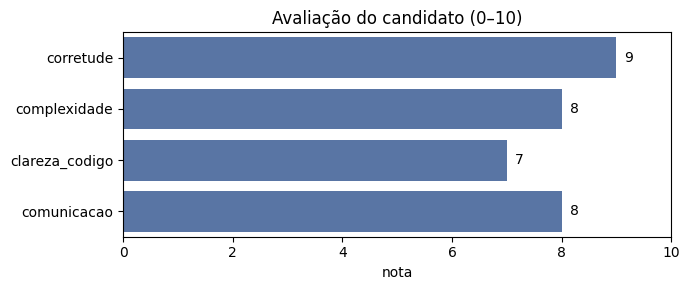

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

avaliacao = agente.avaliar()
notas = avaliacao.model_dump(include={"corretude", "complexidade", "clareza_codigo", "comunicacao"})

display(Markdown(f"### Veredito: **{avaliacao.veredito}**\n\n{avaliacao.resumo}\n\n"
                 "**Pontos fortes:**\n" + "\n".join(f"- {p}" for p in avaliacao.pontos_fortes) +
                 "\n\n**A melhorar:**\n" + "\n".join(f"- {p}" for p in avaliacao.pontos_a_melhorar)))

df_notas = pd.DataFrame({"critério": list(notas), "nota": list(notas.values())})
plt.figure(figsize=(7, 3))
ax = sns.barplot(data=df_notas, y="critério", x="nota", color="#4C72B0")
ax.set(xlim=(0, 10), title="Avaliação do candidato (0–10)", xlabel="nota", ylabel="")
for i, v in enumerate(df_notas["nota"]):
    ax.text(v + 0.15, i, str(v), va="center")
plt.tight_layout(); plt.show()

## 9 · Modo interativo — faça você a entrevista

Rode a célula abaixo e converse com o entrevistador. Envie código entre <code>```python</code> e <code>```</code>.
Comandos: **`avaliar`** encerra e mostra o feedback · **`proximo`** pede outro desafio · **`sair`** encerra sem avaliação.

In [26]:
RODAR_INTERATIVO = False   # mude para True para entrevistar você mesmo

def ler_mensagem():
    # Lê várias linhas; uma linha vazia envia a mensagem (permite colar código).
    linhas = []
    while True:
        linha = input("> " if not linhas else "  ")
        if not linha and linhas:
            return "\n".join(linhas)
        if linha:
            linhas.append(linha)
        if linha.strip().lower() in {"sair", "avaliar", "proximo"}:
            return linha.strip().lower()

def entrevista_interativa():
    ag = EntrevistadorAgent(criar_llm())
    print("Digite sua mensagem (linha vazia = enviar).")
    mostrar("🤖 Entrevistador", ag.responder("Olá, estou pronto para a entrevista."))
    while True:
        msg = ler_mensagem()
        if msg == "sair":
            break
        if msg == "avaliar":
            a = ag.avaliar()
            display(Markdown(f"### {a.veredito}\n{a.resumo}"))
            print(a.model_dump_json(indent=2))
            break
        if msg == "proximo":
            msg = "Podemos ir para o próximo desafio, de nível médio?"
        mostrar("🤖 Entrevistador", ag.responder(msg))
    print(f"Tokens usados: {ag.tokens}")

if RODAR_INTERATIVO:
    entrevista_interativa()
else:
    print("Modo interativo desligado. Mude RODAR_INTERATIVO = True e rode esta célula.")

Modo interativo desligado. Mude RODAR_INTERATIVO = True e rode esta célula.


## 10 · Conclusões

* **Agente = LLM + memória + ferramentas.** O LLM decide *quando* rodar os testes; quem executa é o nosso código Python. Assim o feedback se apoia em **resultados reais**, não em "achismo" do modelo.
* **Memória é o histórico reenviado.** Cada turno manda a conversa inteira — o custo em tokens cresce a cada mensagem (ver `agente.tokens`). Uma melhoria seria resumir mensagens antigas.
* **Portabilidade:** o mesmo código roda em Gemini, OpenAI ou Hugging Face trocando só `base_url`, chave e modelo (protocolo Chat Completions).
* **Saída estruturada:** a avaliação final vira dados (Pydantic), o que permite gráficos, ranking de candidatos ou salvar em banco.

**Limitações:** a execução do código não é um sandbox completo; o banco tem só 5 desafios; modelos pequenos podem esquecer de chamar a ferramenta (o *system prompt* reforça isso).

**Próximos passos:** medir tempo de resposta do candidato, desafios de nível difícil, testes ocultos e interface com Gradio.

### Referências
* Notebook da aula — PUCSP-CS-AI-16-AI-LLM
* OpenAI API — Function calling: https://platform.openai.com/docs/guides/function-calling
* Gemini — compatibilidade com OpenAI: https://ai.google.dev/gemini-api/docs/openai
* Hugging Face Inference Providers: https://huggingface.co/docs/inference-providers
* Pydantic: https://docs.pydantic.dev/